<a href="https://colab.research.google.com/github/isabellapolido-coder/Calculo-Num-Lista-1/blob/main/Lista_3_CN_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Questão 1 (Interpolação de Lagrange para encontrar raízes):
A raiz da função $y(x)$ ocorre onde $y=0$. Observando a tabela fornecida, há uma mudança de sinal entre $x = 2$ ($y = 0.8509$) e $x = 2.5$ ($y = -0.4112$). Portanto, a raiz está neste intervalo.   Para 3 pontos (grau 2): Escolhemos os pontos mais próximos da raiz: $x \in \{1.5, 2.0, 2.5\}$.   Para 4 pontos (grau 3): Adicionamos mais um ponto adjacente: $x \in \{1.5, 2.0, 2.5, 3.0\}$.   

 QUESTÃO 1: RAÍZES POR INTERPOLAÇÃO DE LAGRANGE
(a) Polinômio 3 pontos: 
         2
-0.4166 x - 0.6495 x + 3.816
    Raiz encontrada (3 pontos): x = 2.3459

(b) Polinômio 4 pontos: 
        3         2
0.4119 x - 2.888 x + 4.19 x + 0.7273
    Raiz encontrada (4 pontos): x = 2.3386



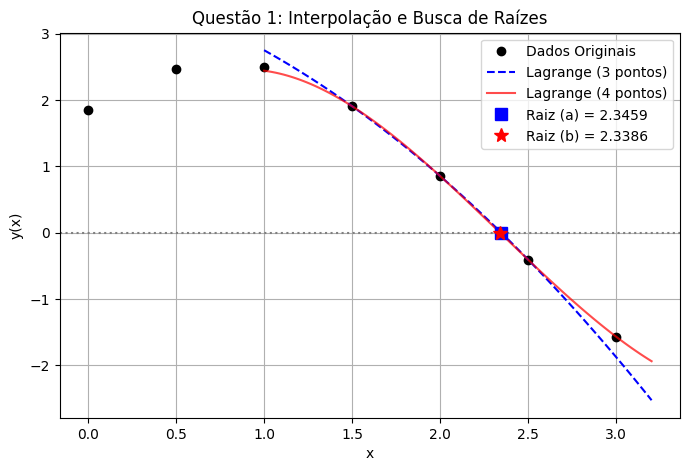

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange
from numpy.polynomial.polynomial import Polynomial

# Dados completos da Questão 1
x_full = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3])
y_full = np.array([1.8421, 2.4694, 2.4921, 1.9047, 0.8509, -0.4112, -1.5727])

print("="*50)
print(" QUESTÃO 1: RAÍZES POR INTERPOLAÇÃO DE LAGRANGE")
print("="*50)

# (a) Três pontos consecutivos (índices 3, 4, 5)
x_3 = x_full[3:6]
y_3 = y_full[3:6]
poly_3 = lagrange(x_3, y_3)
# O lagrange do scipy retorna os coeficientes da maior para a menor potência.
# Para achar a raiz, invertemos os coeficientes e usamos np.roots
raizes_3 = np.roots(poly_3.coef)
# Filtramos apenas a raiz real que cai no nosso intervalo [1.5, 2.5]
raiz_a = [r.real for r in raizes_3 if np.isreal(r) and 1.5 <= r.real <= 2.5][0]
print(f"(a) Polinômio 3 pontos: \n{poly_3}")
print(f"    Raiz encontrada (3 pontos): x = {raiz_a:.4f}\n")

# (b) Quatro pontos consecutivos (índices 3, 4, 5, 6)
x_4 = x_full[3:7]
y_4 = y_full[3:7]
poly_4 = lagrange(x_4, y_4)
raizes_4 = np.roots(poly_4.coef)
raiz_b = [r.real for r in raizes_4 if np.isreal(r) and 1.5 <= r.real <= 3.0][0]
print(f"(b) Polinômio 4 pontos: \n{poly_4}")
print(f"    Raiz encontrada (4 pontos): x = {raiz_b:.4f}\n")

# Gráfico para validar visualmente
x_plot = np.linspace(1, 3.2, 100)
plt.figure(figsize=(8, 5))
plt.plot(x_full, y_full, 'ko', label='Dados Originais')
plt.plot(x_plot, poly_3(x_plot), 'b--', label='Lagrange (3 pontos)')
plt.plot(x_plot, poly_4(x_plot), 'r-', alpha=0.7, label='Lagrange (4 pontos)')
plt.axhline(0, color='gray', linestyle=':')
plt.plot(raiz_a, 0, 'bs', markersize=8, label=f'Raiz (a) = {raiz_a:.4f}')
plt.plot(raiz_b, 0, 'r*', markersize=10, label=f'Raiz (b) = {raiz_b:.4f}')
plt.title('Questão 1: Interpolação e Busca de Raízes')
plt.xlabel('x'); plt.ylabel('y(x)')
plt.legend(); plt.grid(True)
plt.show()

Questões 2 e 3 (Polinômio e a "Pegadinha" do Modelo Exponencial):
Na Questão 2, os dados fornecidos são $p(-1)=-32$, $p(2)=1$, $p(4)=3$. Com 3 pontos, a interpolação de Lagrange fornecerá um polinômio exato de grau 2.   Para a Questão 3, o enunciado pede para usar os mesmos dados da questão anterior para ajustar um modelo exponencial $y = a e^{bx}$ usando Mínimos Quadrados. Aqui há um ponto crítico: é matematicamente impossível que um modelo exponencial da forma $y = a e^{bx}$ (onde $a$ e $b$ são reais) assuma valores negativos e positivos simultaneamente. Como $e^{bx}$ é estritamente positivo para qualquer $x$ real, o sinal de $y$ dependerá exclusivamente do sinal de $a$. Os dados da Questão 2 contêm $y = -32$ e $y = 1$. A linearização padrão do MMQ exigiria aplicar $\ln(y)$, o que resultará em um erro matemático (logaritmo de número negativo).

In [ ]:
print("="*50)
print(" QUESTÃO 2: POLINÔMIO INTERPOLADOR (GRAU 2)")
print("="*50)

# Dados da Questão 2
x_q2 = np.array([-1, 2, 4])
y_q2 = np.array([-32, 1, 3])

# Interpolação de Lagrange
poly_q2 = lagrange(x_q2, y_q2)

# O Scipy formata o polinômio do maior para o menor grau (ax^2 + bx + c)
print(f"Polinômio p(x) gerado:\n{poly_q2}\n")

# Comprovação (Verificação)
print("Verificação dos nós:")
for xi, yi in zip(x_q2, y_q2):
    print(f"p({xi}) = {poly_q2(xi):.1f} (Esperado: {yi})")


print("\n" + "="*50)
print(" QUESTÃO 3: MÍNIMOS QUADRADOS - MODELO EXPONENCIAL")
print("="*50)

print("""ANÁLISE CRÍTICA:
O modelo exponencial proposto é y = a * e^(bx).
Ao aplicar a linearização para o Método dos Mínimos Quadrados, aplicamos
o logaritmo natural em ambos os lados: ln(y) = ln(a) + bx.

Contudo, os dados da Questão 2 possuem y = -32 (um valor negativo) e y = 1, y = 3
(valores positivos). É matematicamente impossível calcular ln(-32) no conjunto
dos números reais.

Fisicamente, a função y = a * e^(bx) nunca cruza o eixo X (ela é estritamente
positiva se a > 0, ou estritamente negativa se a < 0). Portanto, ela não pode
modelar dados que mudam de sinal.

Abaixo, o código tentará realizar a linearização e o NumPy emitirá um aviso
(RuntimeWarning) de valor inválido, resultando em 'nan' (Not a Number).""")

# Tentativa de Linearização do modelo exponencial (Y = ln(y))
try:
    # A linha abaixo vai gerar um aviso proposital para documentar no projeto
    Y_linearizado = np.log(y_q2)
    print("\nValores de ln(y):", Y_linearizado)
except Exception as e:
    print(f"Erro capturado: {e}")

 QUESTÃO 2: POLINÔMIO INTERPOLADOR (GRAU 2)
Polinômio p(x) gerado:
    2
-2 x + 13 x - 17

Verificação dos nós:
p(-1) = -32.0 (Esperado: -32)
p(2) = 1.0 (Esperado: 1)
p(4) = 3.0 (Esperado: 3)

 QUESTÃO 3: MÍNIMOS QUADRADOS - MODELO EXPONENCIAL
ANÁLISE CRÍTICA:
O modelo exponencial proposto é y = a * e^(bx).
Ao aplicar a linearização para o Método dos Mínimos Quadrados, aplicamos 
o logaritmo natural em ambos os lados: ln(y) = ln(a) + bx.

Contudo, os dados da Questão 2 possuem y = -32 (um valor negativo) e y = 1, y = 3 
(valores positivos). É matematicamente impossível calcular ln(-32) no conjunto 
dos números reais. 

Fisicamente, a função y = a * e^(bx) nunca cruza o eixo X (ela é estritamente 
positiva se a > 0, ou estritamente negativa se a < 0). Portanto, ela não pode 
modelar dados que mudam de sinal.

Abaixo, o código tentará realizar a linearização e o NumPy emitirá um aviso 
(RuntimeWarning) de valor inválido, resultando em 'nan' (Not a Number).

Valores de ln(y): [       nan 

/tmp/ipykernel_797/3929363582.py:44: RuntimeWarning: invalid value encountered in log
  Y_linearizado = np.log(y_q2)
